## Harder settings: reduced questionnaire and noisy answers

With all ten answers available, the label can be computed exactly from the inputs (notebook 02), so the best models reach 100% and the comparison between them says little. This notebook makes the task harder in two ways that have a practical meaning:

1. **Reduced questionnaire.** The model sees only the top 4, 6 or 8 questions (chosen by chi-square on the training fold) plus age, sex, jaundice and family history, and has to predict the full-questionnaire outcome. This asks how much a shorter screen loses, and which models recover the most from partial information.
2. **Noisy answers.** Models are trained on clean data and tested with 5%, 10% or 20% of the answers flipped at random, as would happen with careless or inconsistent answering.

Settings are fixed (no grid search); they are the values the tuning in notebook 05 chose most often. Stratified 5-fold cross-validation, repeated twice.

In [1]:
from tabpfn import TabPFNClassifier  # must be imported before LightGBM, or the notebook can crash

import time
from pathlib import Path

import numpy as np
import pandas as pd
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline
from interpret.glassbox import ExplainableBoostingClassifier
from lightgbm import LGBMClassifier
from scipy.stats import chi2_contingency
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, recall_score, roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

PROCESSED = Path("../data/processed")
TABLES = Path("../results/tables")

SEED = 42
RERUN = True

GROUPS = ["toddler", "child", "adolescent", "adult"]
QUESTIONS = [f"A{i}" for i in range(1, 11)]
DETAILS = ["age", "male", "jaundice", "family_asd"]
MODEL_NAMES = ["Logistic Regression", "Random Forest", "XGBoost", "LightGBM", "EBM", "TabPFN"]

# how many questions we keep in the short questionnaire
K_VALUES = [4, 6, 8]
# share of answers we change in the noise test (5%, 10%, 20%)
NOISE_LEVELS = [0.05, 0.10, 0.20]

data = {g: pd.read_csv(PROCESSED / f"{g}.csv") for g in GROUPS}

In [2]:
# the settings are fixed here, there is no tuning
def get_classifier(name):
    if name == "Logistic Regression":
        return LogisticRegression(C=1, max_iter=2000)
    if name == "Random Forest":
        return RandomForestClassifier(n_estimators=500, max_depth=5, random_state=SEED, n_jobs=1)
    if name == "XGBoost":
        return XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.1, random_state=SEED, n_jobs=1, eval_metric="logloss")
    if name == "LightGBM":
        return LGBMClassifier(n_estimators=300, num_leaves=7, learning_rate=0.1, min_child_samples=10, random_state=SEED, n_jobs=1, verbose=-1)
    if name == "EBM":
        return ExplainableBoostingClassifier(interactions=0, random_state=SEED, n_jobs=1)
    if name == "TabPFN":
        return TabPFNClassifier(device="cpu", random_state=SEED, ignore_pretraining_limits=True)


# same pipeline as in notebook 05, but without the settings to try.
# SMOTE makes new rows for the smaller class, e.g. 40 "yes" rows become 100
def make_pipeline(name, features):
    categorical = [i for i, f in enumerate(features) if f != "age"]
    steps = [("smote", SMOTENC(categorical_features=categorical, random_state=SEED))]
    if name == "Logistic Regression":
        steps.append(("scale", StandardScaler()))
    steps.append(("clf", get_classifier(name)))
    return Pipeline(steps)


def top_questions(df, k):
    # pick the k questions most related to the label, using training data only
    stats = {q: chi2_contingency(pd.crosstab(df[q], df["asd"]))[0] for q in QUESTIONS}
    return sorted(stats, key=stats.get, reverse=True)[:k]


# change each answer (0 to 1, or 1 to 0) with chance p
def flip_answers(X, p, rng):
    X = X.copy()
    # True where an answer will be changed
    mask = rng.random(X[QUESTIONS].shape) < p
    X[QUESTIONS] = np.where(mask, 1 - X[QUESTIONS].values, X[QUESTIONS].values)
    return X


def evaluate(model, X, y):
    prob = model.predict_proba(X)[:, 1]
    return {"roc_auc": roc_auc_score(y, prob), "recall": recall_score(y, prob >= 0.5),
            "accuracy": ((prob >= 0.5) == y).mean(), "brier": brier_score_loss(y, prob)}

### Running both experiments

One cross-validation loop. In each fold every model is fitted once on all ten questions (used for the clean and noisy tests) and once per reduced set.

In [3]:
if RERUN or not (TABLES / "harder_settings.csv").exists():
    rows = []
    # 5 folds, done 2 times = 10 test folds
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
    for g in GROUPS:
        df = data[g]
        start = time.time()
        for fold, (train, test) in enumerate(cv.split(df, df["asd"])):
            tr, te = df.iloc[train], df.iloc[test]
            # each fold gets different noise, but it is the same on every run
            rng = np.random.default_rng(SEED + fold)
            # noise is added to the test answers only. The models train on clean data
            noisy = {p: flip_answers(te, p, rng) for p in NOISE_LEVELS}
            # the questions are picked from the training data only
            subsets = {k: top_questions(tr, k) for k in K_VALUES}
            for name in MODEL_NAMES:
                full = QUESTIONS + DETAILS
                # first with all ten questions and no noise
                model = make_pipeline(name, full).fit(tr[full], tr["asd"])
                rows.append({"group": g, "fold": fold, "model": name, "setting": "questions", "value": 10,
                             **evaluate(model, te[full], te["asd"])})
                # the same model, now tested on the noisy answers
                for p, te_noisy in noisy.items():
                    rows.append({"group": g, "fold": fold, "model": name, "setting": "noise", "value": p,
                                 **evaluate(model, te_noisy[full], te["asd"])})
                # train a new model for each shorter questionnaire
                for k, qs in subsets.items():
                    feats = qs + DETAILS
                    model = make_pipeline(name, feats).fit(tr[feats], tr["asd"])
                    rows.append({"group": g, "fold": fold, "model": name, "setting": "questions", "value": k,
                                 "questions": " ".join(qs), **evaluate(model, te[feats], te["asd"])})
        print(f"{g:<11} done in {time.time() - start:.0f}s")
    results = pd.DataFrame(rows)
    results.to_csv(TABLES / "harder_settings.csv", index=False)
else:
    results = pd.read_csv(TABLES / "harder_settings.csv")

toddler     done in 1223s


child       done in 415s


adolescent  done in 262s


adult       done in 1051s


### Reduced questionnaire

In [4]:
q = results[results.setting == "questions"]
# average ROC-AUC for each number of questions
auc = q.pivot_table(index=["group", "model"], columns="value", values="roc_auc").loc[GROUPS].loc[:, [4, 6, 8, 10]]
auc.round(3)

value                            4.0    6.0    8.0    10.0
group      model                                          
toddler    EBM                  0.952  0.975  0.990  1.000
           LightGBM             0.938  0.965  0.985  0.998
           Logistic Regression  0.953  0.976  0.990  1.000
           Random Forest        0.948  0.971  0.985  0.992
           TabPFN               0.951  0.975  0.990  1.000
           XGBoost              0.940  0.967  0.987  0.999
child      EBM                  0.886  0.945  0.980  1.000
           LightGBM             0.865  0.927  0.960  0.990
           Logistic Regression  0.880  0.946  0.980  1.000
           Random Forest        0.885  0.940  0.974  0.988
           TabPFN               0.884  0.945  0.979  1.000
           XGBoost              0.876  0.935  0.966  0.990
adolescent EBM                  0.867  0.920  0.938  0.985
           LightGBM             0.844  0.911  0.921  0.969
           Logistic Regression  0.868  0.936  0.946  0.991
           Random Forest        0.870  0.934  0.956  0.978
           TabPFN               0.867  0.934  0.954  0.989
           XGBoost              0.870  0.917  0.943  0.967
adult      EBM                  0.954  0.968  0.984  1.000
           LightGBM             0.938  0.959  0.980  0.995
           Logistic Regression  0.953  0.970  0.987  1.000
           Random Forest        0.955  0.969  0.983  0.995
           TabPFN               0.953  0.971  0.987  1.000
           XGBoost              0.946  0.963  0.981  0.998

In [5]:
rec = q.pivot_table(index=["group", "model"], columns="value", values="recall").loc[GROUPS].loc[:, [4, 6, 8, 10]]
rec.round(3)

value                            4.0    6.0    8.0    10.0
group      model                                          
toddler    EBM                  0.896  0.914  0.967  1.000
           LightGBM             0.880  0.925  0.957  0.983
           Logistic Regression  0.896  0.916  0.964  1.000
           Random Forest        0.891  0.914  0.943  0.954
           TabPFN               0.888  0.913  0.975  1.000
           XGBoost              0.880  0.921  0.954  0.986
child      EBM                  0.819  0.865  0.917  1.000
           LightGBM             0.797  0.850  0.895  0.951
           Logistic Regression  0.808  0.857  0.936  1.000
           Random Forest        0.816  0.888  0.914  0.959
           TabPFN               0.804  0.868  0.925  0.989
           XGBoost              0.812  0.861  0.884  0.974
adolescent EBM                  0.833  0.892  0.883  0.983
           LightGBM             0.792  0.883  0.883  0.958
           Logistic Regression  0.833  0.925  0.883  0.975
           Random Forest        0.850  0.892  0.908  0.958
           TabPFN               0.850  0.892  0.917  0.975
           XGBoost              0.808  0.892  0.900  0.967
adult      EBM                  0.835  0.903  0.903  1.000
           LightGBM             0.786  0.832  0.862  0.927
           Logistic Regression  0.835  0.919  0.895  1.000
           Random Forest        0.830  0.922  0.900  0.938
           TabPFN               0.835  0.908  0.903  1.000
           XGBoost              0.832  0.846  0.881  0.981

In [6]:
# which questions were picked most often when 6 are kept
sel = q[(q.value == 6) & (q.model == "EBM")].groupby("group")["questions"].agg(
    lambda s: pd.Series(" ".join(s).split()).value_counts().head(6).to_dict())
sel.to_frame("questions chosen (count over 10 folds)")

,questions chosen (count over 10 folds)
group,
adolescent,"{'A4': 10, 'A5': 10, 'A3': 10, 'A10': 10, 'A6'..."
adult,"{'A9': 10, 'A6': 10, 'A5': 10, 'A4': 10, 'A3':..."
child,"{'A4': 10, 'A9': 10, 'A8': 10, 'A10': 10, 'A6'..."
toddler,"{'A7': 10, 'A6': 10, 'A9': 10, 'A5': 10, 'A1':..."


### Noisy answers

In [7]:
n = results[results.setting == "noise"]
clean = q[q.value == 10].set_index(["group", "model", "fold"])["roc_auc"]
noise_auc = n.pivot_table(index=["group", "model"], columns="value", values="roc_auc").loc[GROUPS]
# add the result without noise as the 0% column
noise_auc.insert(0, 0.0, q[q.value == 10].groupby(["group", "model"])["roc_auc"].mean())
noise_auc.round(3)

value                            0.00   0.05   0.10   0.20
group      model                                          
toddler    EBM                  1.000  0.983  0.956  0.869
           LightGBM             0.998  0.982  0.965  0.895
           Logistic Regression  1.000  0.986  0.968  0.903
           Random Forest        0.992  0.978  0.963  0.900
           TabPFN               1.000  0.985  0.966  0.901
           XGBoost              0.999  0.983  0.967  0.898
child      EBM                  1.000  0.968  0.940  0.849
           LightGBM             0.990  0.955  0.930  0.821
           Logistic Regression  1.000  0.969  0.940  0.844
           Random Forest        0.988  0.959  0.932  0.826
           TabPFN               1.000  0.966  0.939  0.837
           XGBoost              0.990  0.961  0.928  0.825
adolescent EBM                  0.985  0.973  0.902  0.870
           LightGBM             0.969  0.952  0.875  0.845
           Logistic Regression  0.991  0.977  0.901  0.878
           Random Forest        0.978  0.965  0.884  0.854
           TabPFN               0.989  0.976  0.891  0.881
           XGBoost              0.967  0.955  0.869  0.824
adult      EBM                  1.000  0.985  0.962  0.897
           LightGBM             0.995  0.980  0.962  0.887
           Logistic Regression  1.000  0.986  0.965  0.900
           Random Forest        0.995  0.980  0.962  0.895
           TabPFN               1.000  0.987  0.969  0.902
           XGBoost              0.998  0.984  0.967  0.894

### Figures

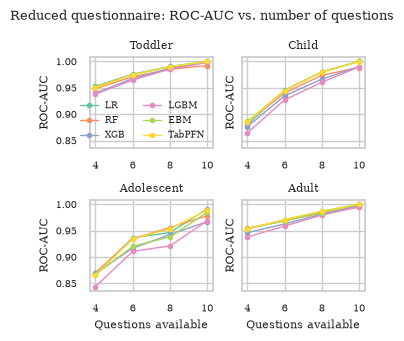

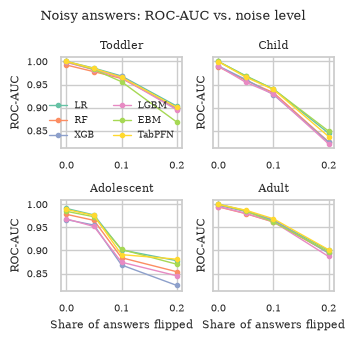

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

FIGURES = Path("../results/figures")
COLUMN, PAGE = 3.5, 7.16
sns.set_theme(style="whitegrid", font="serif", rc={
    "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 6.5,
    "figure.titlesize": 9, "savefig.dpi": 300, "savefig.bbox": "tight",
})
SHORT = {"Logistic Regression": "LR", "Random Forest": "RF", "XGBoost": "XGB",
         "LightGBM": "LGBM", "EBM": "EBM", "TabPFN": "TabPFN"}
palette = dict(zip(SHORT.values(), sns.color_palette("Set2", 6)))


# one line for each model, one small plot for each age group
def lines(frame, xlabel, title, filename):
    fig, axes = plt.subplots(2, 2, figsize=(COLUMN, 3.4), sharey=True)
    for ax, g in zip(axes.flat, GROUPS):
        for m in MODEL_NAMES:
            s = frame.loc[(g, m)]
            ax.plot(s.index, s.values, marker="o", ms=3, lw=1, label=SHORT[m], color=palette[SHORT[m]])
        ax.set_title(g.capitalize())
        ax.set_ylabel("ROC-AUC")
    for ax in axes[1]:
        ax.set_xlabel(xlabel)
    axes[0, 0].legend(ncol=2, frameon=False, loc="lower right")
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(FIGURES / filename)


lines(auc, "Questions available", "Reduced questionnaire: ROC-AUC vs. number of questions", "fig_reduced_questions.png")
lines(noise_auc, "Share of answers flipped", "Noisy answers: ROC-AUC vs. noise level", "fig_noise.png")

### What this shows

**Reduced questionnaire.** Once the model no longer sees all ten answers, nobody is perfect and the models separate. With 8 of 10 questions, ROC-AUC is 0.98–0.99 for toddlers, children and adults, but recall drops to about 0.90–0.97, so roughly one positive case in twenty is missed. With 6 questions it is 0.92–0.98 ROC-AUC and recall 0.85–0.93; with 4 questions, 0.87–0.96 and recall 0.80–0.90. Logistic Regression, EBM and TabPFN are tied at the top at every k; LightGBM is consistently lowest (by 0.01–0.03), with XGBoost and Random Forest in between. The questions chosen by chi-square are stable across folds: for adults A3, A4, A5, A6, A9, A10 in all ten folds; for toddlers A1, A4, A5, A6, A7, A9. So a shorter screen of 8 items keeps most of the ranking power but costs some recall, which is the metric that matters most in screening.

**Noisy answers.** Flipping 5% of answers costs about 0.02 ROC-AUC, 10% about 0.04–0.06, and 20% about 0.10–0.15, in every group. The models that were perfect on clean data degrade at the same rate as the others: there is no sign that LR, EBM or TabPFN are more fragile. The one exception is EBM for toddlers at 20% noise (0.869 vs 0.90 for the rest), where its sharp per-question step functions seem to overreact to flipped answers. Adolescents (101 records) are hit hardest, falling to 0.82–0.88 at 20% noise.

**Taken together.** The full-questionnaire result (100%) measures whether a model can represent the scoring rule; these two settings measure how well it works when the rule's inputs are incomplete or unreliable, which is closer to real screening. Under both, the simple linear model is as good as anything else, EBM matches it while staying readable, TabPFN gains nothing on this data, and the gradient-boosted trees are a step behind.